# Loading Libraries and Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.datasets import fetch_california_housing

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [ ]:
import os

# Local data folder (same directory as this notebook)
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

data_set = pd.read_csv(os.path.join(DATA_DIR, 'data_set_final.csv'), encoding='utf-8',sep=",")

# Data Preparation

In [3]:
from sklearn.model_selection import train_test_split

X = data_set.drop('PRESENCA_COMPLETA', axis=1)
y = data_set['PRESENCA_COMPLETA']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [4]:
from sklearn.preprocessing import StandardScaler

# Identify columns to scale
cols_to_scale = [col for col in X_train.columns if 'QT_' in col or '_POR_' in col]

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform on the training data
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

# Transform the test data
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Transformation applied to columns:", cols_to_scale)
display(X_train.head())
display(X_test.head())

Transformation applied to columns: ['QT_SALAS_UTILIZADAS', 'QT_SALAS_UTILIZA_CLIMATIZADAS', 'QT_MAT_EJA_MED', 'QT_MAT_MED', 'QT_DOC_MED', 'QT_TUR_MED', 'QT_MAT_PROF', 'QT_DOC_PROF', 'MAT_MED_POR_TURMA', 'MAT_MED_POR_SALA', 'MAT_MED_POR_DOC_MED', 'DOC_MED_POR_TURMA_MED']


,CO_ESCOLA,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,SG_UF_CODED,NO_REGIAO_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO
14970,35023760,2,0.0,1,0.0,0,0,1,0,0,0,0,1,0,1,1,1,1,0,-0.279997,-0.708946,1,1,1,1,1,1,0,1,0,0,0,0,1,1,0,0,1,0,0,1,1,1,1,1,0,0,0,-0.243512,-0.771546,-0.572766,-0.845128,-0.304066,-0.385669,1,0.0,1,1000000,0.110255,-0.700094,0.0,-0.766809,1.453910,203,200,1,0,4,0,1,10000000000
4934,25016032,2,0.0,1,0.0,1,0,1,1,0,0,0,1,0,0,1,0,1,0,-0.519926,-0.234515,1,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,1,0,1,0,1,1,0,0,-0.073268,-0.996777,-0.852762,-0.845128,-0.304066,-0.385669,1,0.0,1,1000001,-2.308694,-0.887379,1.0,-1.201141,0.552707,104,100,1,0,3,0,0,10000000000
8008,29385253,2,0.0,1,0.0,1,0,1,1,0,0,0,1,0,0,1,1,1,0,-0.327983,0.145030,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,0.348643,1.331816,0.477218,1.317115,0.400227,0.821089,0,0.0,1,1000000,0.461336,2.517751,1.0,1.244575,-0.965109,108,100,1,0,3,1,1,10000000000
23763,51050765,2,0.0,1,0.0,1,0,1,1,0,0,1,0,0,1,1,0,1,0,-0.327983,0.145030,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,1,0,1,0,1,0,1,1,1,0,0,0,-0.243512,-0.738852,-0.362769,-0.725004,-0.304066,-0.385669,1,0.0,1,1000000,-0.465518,-0.603495,1.0,-0.821866,1.115112,401,400,1,0,3,1,1,10000000000
15100,35026323,2,0.0,1,0.0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0.055904,-0.708946,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,1,1,1,0,1,-0.243512,0.329177,-0.222771,0.115869,2.664028,2.698268,1,0.0,1,1000010,0.893166,0.003701,0.0,0.911791,-0.700846,203,200,1,1,3,1,1,10000000


,CO_ESCOLA,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,SG_UF_CODED,NO_REGIAO_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO
25173,53068092,2,0.0,1,0.0,1,0,1,0,0,0,1,0,0,1,0,1,1,0,-0.040067,-0.708946,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,0,1,0,1,0,1,1,0,0,0.363447,2.120122,1.737199,2.878736,-0.304066,-0.385669,1,0.0,1,1000000,-0.209229,1.774034,0.0,0.780880,-0.978661,403,400,1,0,3,0,1,10000000000
11868,33026734,2,0.0,2,0.0,1,0,1,1,0,0,0,1,0,1,1,1,1,0,-0.615898,-0.424287,1,0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,1,0,0,0,-0.243512,-0.771546,-0.992760,-0.845128,-0.304066,-0.385669,1,0.0,1,1000000,0.110255,0.289064,1.0,-0.298221,0.098717,202,200,1,0,4,1,1,10000000000
22906,43167489,2,0.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,0.247848,-0.708946,1,0,0,1,0,1,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,1,0,0,0,-0.243512,1.041196,0.757214,0.836617,-0.304066,-0.385669,1,0.0,1,1000000,0.781991,0.249143,0.0,0.637734,-0.578879,302,300,0,0,3,0,1,10000000000
19095,35923977,2,0.0,1,0.0,0,0,1,0,0,0,0,1,0,1,1,1,1,0,-0.184025,-0.708946,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,0,1,0,0,1,-0.243512,1.458962,1.527203,1.317115,0.088326,-0.050458,0,0.0,1,1000000,0.655601,1.750869,0.0,0.435861,-0.484015,203,200,1,0,3,0,1,10000000000
3834,23079533,2,0.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,-0.279997,0.239917,1,1,0,1,1,0,0,0,0,0,0,1,1,1,1,0,0,0,1,1,0,1,1,1,0,0,0,-0.243512,0.271053,-0.012774,-0.004256,-0.304066,-0.385669,1,1.0,1,1000000,1.120199,0.714397,1.0,0.516610,-0.375600,102,100,1,0,3,0,1,10000000000


In [5]:
columns_to_drop = ["CO_ESCOLA","NO_REGIAO_CODED"]
data_set = data_set.drop(columns=columns_to_drop)

# 1️⃣ Categorical columns
categorical_cols = [
    'SG_UF_CODED',
    'TP_DEPENDENCIA',
    'TP_CATEGORIA_ESCOLA_PRIVADA',
    'TP_LOCALIZACAO',
    'VINCULO',
    # 'LOCAL_FUNC'
]

# 2️⃣ Convert to 'category' type
for col in categorical_cols:
    data_set[col] = data_set[col].astype('category')

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

display(data_set)
# X = all columns except PRESENCA_COMPLETA
X = data_set.drop('PRESENCA_COMPLETA', axis=1)
y = data_set['PRESENCA_COMPLETA']

# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,PRESENCA_COMPLETA,SG_UF_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO
0,4,1.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,38,38,1,0,0,1,1,1,0,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,1,1,0,0,0,0,353,28,8,0,0,1,0.0,1,1000000,44.12,9.29,1.00,12.61,3.50,0.978495,0,1,1,3,1,1,1000000
1,4,1.0,1,1.0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,44,44,1,1,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,1,0,0,0,0,188,26,6,0,0,1,0.0,1,1000001,31.33,4.27,1.00,7.23,4.33,0.903846,0,1,1,4,1,1,1000000
2,4,1.0,1,0.0,0,1,1,1,0,0,1,0,1,1,0,1,1,0,25,25,1,0,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,1,0,0,0,0,105,22,5,0,0,1,0.0,1,1000000,21.00,4.20,1.00,4.77,4.40,0.944444,0,1,1,4,1,0,1000000
3,2,0.0,1,0.0,1,1,1,1,0,0,1,0,0,1,1,0,1,0,33,33,1,1,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,411,27,16,0,0,1,1.0,1,1000000,25.69,12.45,1.00,15.22,1.69,0.925234,0,1,0,3,0,0,11000000000
4,2,0.0,1,0.0,0,1,1,1,0,0,1,1,0,1,1,0,1,0,17,17,1,1,0,1,1,1,0,0,0,0,0,1,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,180,192,20,6,0,0,1,0.0,1,1000000,32.00,11.29,1.00,9.60,3.33,0.333333,0,1,0,3,0,1,10000000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25173,2,0.0,1,0.0,1,0,1,0,0,0,1,0,0,1,0,1,1,0,15,0,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,0,1,0,1,0,1,1,0,0,82,882,48,34,0,0,1,0.0,1,1000000,25.94,58.80,0.00,18.38,1.41,0.834711,403,1,0,3,0,1,10000000000
25174,2,0.0,1,0.0,0,1,1,0,0,0,0,1,0,1,0,1,1,0,22,22,1,0,0,1,1,1,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,909,47,38,0,0,1,0.0,1,1101000,23.92,41.32,1.00,19.34,1.24,0.766667,403,1,0,3,1,1,10000000000
25175,4,1.0,1,0.0,0,0,1,1,0,0,1,1,0,1,1,1,1,0,23,4,1,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,0,0,0,0,40,12,3,0,0,1,0.0,1,1000001,13.33,1.74,0.17,3.33,4.00,0.800000,403,1,1,4,1,1,1000000
25176,4,1.0,1,0.0,0,0,1,0,0,0,1,1,0,1,0,1,1,0,16,0,1,0,0,1,1,1,0,0,0,0,0,0,1,1,0,1,1,0,0,1,0,0,0,1,0,0,0,0,61,12,3,0,0,1,0.0,1,1000000,20.33,3.81,0.00,5.08,4.00,1.000000,403,1,1,4,0,1,1000000


# Modeling - Random Forest Regressor

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Assuming X_train and y_train are already defined

# 5️⃣ Create the model
rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)

# 6️⃣ Train the model
rf_reg.fit(X_train, y_train)

# 7️⃣ Evaluate on the training set
y_pred_rf_train = rf_reg.predict(X_train)

rmse_rf_train = np.sqrt(mean_squared_error(y_train, y_pred_rf_train))
r2_rf_train = r2_score(y_train, y_pred_rf_train)

print(f"✅ Training RMSE (RandomForestRegressor): {rmse_rf_train:.4f}")
print(f"✅ Training R² (RandomForestRegressor): {r2_rf_train:.4f}")

✅ RMSE no treino (RandomForestRegressor): 0.0483
✅ R² no treino (RandomForestRegressor): 0.9348


# Model Evaluation - Random Forest Regressor

In [7]:
# Assuming y_test and y_pred_rf_test are available (predictions on the test set for RandomForestRegressor)
# If y_pred_rf_test is not available, we need to make predictions on the test set first.

# Make predictions on the test set for RandomForestRegressor
if 'y_pred_rf_test' not in globals():
    # Assuming rf_reg is the trained RandomForestRegressor model
    y_pred_rf_test = rf_reg.predict(X_test)

comparison_df_rf = pd.DataFrame({'True Values': y_test, 'Predicted Values': y_pred_rf_test})
comparison_df_rf['True Values'] = comparison_df_rf['True Values'].astype(float)
comparison_df_rf['Predicted Values'] = comparison_df_rf['Predicted Values'].astype(float)

display(comparison_df_rf)

,Valores Verdadeiros,Valores Preditos
25173,0.834711,0.734933
11868,0.210526,0.695810
22906,0.794872,0.783657
19095,0.721805,0.733490
3834,0.791667,0.895917
...,...,...
2199,0.735294,0.717957
15272,0.750000,0.679070
4139,0.964286,0.952236
3505,1.000000,0.957907


# Classification and Confusion Matrix (Random Forest Regressor)

In [8]:
# Define the categories based on the thresholds
def classify_presence(value):
    if value > 0.90:
        return 'High'
    else:
      return 'Not-High'

# Apply the classification to the true and predicted values
y_test_classified = y_test.apply(classify_presence)
y_pred_classified = pd.Series(y_pred_rf_test).apply(classify_presence)

# Reindex y_pred_classified to align with y_test_classified
y_pred_classified.index = y_test_classified.index

# Show the classifications to verify
display(pd.DataFrame({'Classified True Values': y_test_classified, 'Classified Predicted Values': y_pred_classified}))

,Valores Verdadeiros Classificados,Valores Preditos Classificados
25173,Não-Alta,Não-Alta
11868,Não-Alta,Não-Alta
22906,Não-Alta,Não-Alta
19095,Não-Alta,Não-Alta
3834,Não-Alta,Não-Alta
...,...,...
2199,Não-Alta,Não-Alta
15272,Não-Alta,Não-Alta
4139,Alta,Alta
3505,Alta,Alta


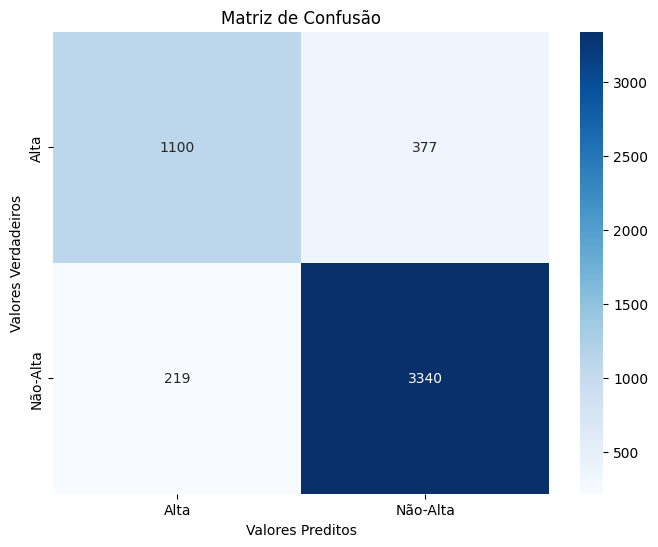

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

categories = ['High', 'Not-High']

# Compute the confusion matrix
cm = confusion_matrix(y_test_classified, y_pred_classified, labels=categories)

# Show the confusion matrix as a heatmap for better visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories)
plt.xlabel('Predicted Values')
plt.ylabel('True Values')
plt.title('Confusion Matrix')
plt.show()

# Classification Metrics (Random Forest Regressor)

In [10]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compute accuracy
accuracy = accuracy_score(y_test_classified, y_pred_classified)
print(f"Accuracy: {accuracy:.4f}")

# Compute F1-score (using 'weighted' to handle class imbalance, if any)
f1 = f1_score(y_test_classified, y_pred_classified, average='weighted')
print(f"F1-Score (weighted): {f1:.4f}")

# Compute recall (using 'weighted' to handle class imbalance, if any)
recall = recall_score(y_test_classified, y_pred_classified, average='weighted')
print(f"Recall (weighted): {recall:.4f}")

Acurácia: 0.8817
F1-Score (weighted): 0.8796
Recall (weighted): 0.8817


# Modeling - HistGradientBoostingRegressor

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 3️⃣ Define X and y
X = data_set.drop(columns=['PRESENCA_COMPLETA'])
y = data_set['PRESENCA_COMPLETA']

# 4️⃣ Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5️⃣ Create the model
model = HistGradientBoostingRegressor(
    max_iter=300,           # ← replaces n_estimators
    max_depth=10,
    learning_rate=0.05,
    min_samples_leaf=2,
    random_state=42
)

# ⚠️ older versions do not accept categorical_features
# The model detects categories automatically if dtype='category'

# 6️⃣ Train the model
model.fit(X_train, y_train)

# 7️⃣ Evaluate on the training set
y_pred = model.predict(X_train)

rmse = np.sqrt(mean_squared_error(y_train, y_pred))
r2 = r2_score(y_train, y_pred)

print(f"✅ Training RMSE: {rmse:.4f}")
print(f"✅ Training R²: {r2:.4f}")

✅ RMSE no treino: 0.1170
✅ R² no treino: 0.6178


# Model Evaluation - HistGradientBoostingRegressor

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

# 6️⃣ Train the model
model.fit(X_train, y_train)

# 7️⃣ Predict on the test set
y_pred = model.predict(X_test)

In [13]:
# Evaluate on the test set
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
r2_test = r2_score(y_test, y_pred)

print(f"✅ Test RMSE: {rmse_test:.4f}")
print(f"✅ Test R²: {r2_test:.4f}")

✅ RMSE no teste: 0.1263
✅ R² no teste: 0.5490


In [14]:
comparison_df = pd.DataFrame({'True Values': y_test, 'Predicted Values': y_pred})
comparison_df['True Values'] = comparison_df['True Values'].astype(float)
comparison_df['Predicted Values'] = comparison_df['Predicted Values'].astype(float)
display(comparison_df)

,Valores Verdadeiros,Valores Preditos
25173,0.834711,0.751518
11868,0.210526,0.711226
22906,0.794872,0.767387
19095,0.721805,0.722132
3834,0.791667,0.901728
...,...,...
2199,0.735294,0.714095
15272,0.750000,0.683181
4139,0.964286,0.930696
3505,1.000000,0.959678


# Classification and Confusion Matrix (HistGradientBoostingRegressor)

In [15]:
# Predictions on the test set
y_pred_test = model.predict(X_test)

# Classify into High / Not-High
y_test_classified = y_test.apply(classify_presence)
y_pred_classified = pd.Series(y_pred_test, index=y_test.index).apply(classify_presence)

# Comparison
comparison = pd.DataFrame({
    'True Value (Class)': y_test_classified,
    'Predicted Value (Class)': y_pred_classified,
    'True Value (Continuous)': y_test,
    'Predicted Value (Continuous)': y_pred_test
})

display(comparison.head(10))

,Valor Verdadeiro (Classe),Valor Predito (Classe),Valor Verdadeiro (Contínuo),Valor Predito (Contínuo)
25173,Não-Alta,Não-Alta,0.834711,0.751518
11868,Não-Alta,Não-Alta,0.210526,0.711226
22906,Não-Alta,Não-Alta,0.794872,0.767387
19095,Não-Alta,Não-Alta,0.721805,0.722132
3834,Não-Alta,Alta,0.791667,0.901728
21731,Alta,Alta,0.928571,0.909247
8100,Não-Alta,Não-Alta,0.689655,0.667535
8470,Alta,Alta,1.000000,0.965279
18569,Não-Alta,Não-Alta,0.513514,0.644725
19258,Não-Alta,Não-Alta,0.444444,0.621512


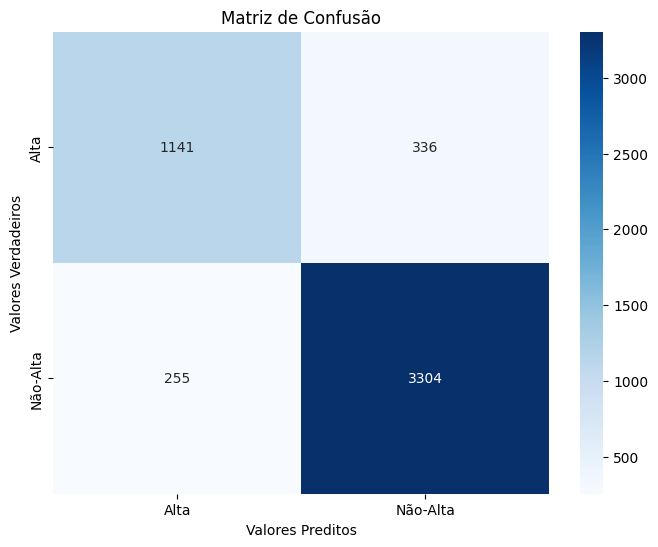

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

categories = ['High', 'Not-High']

# Compute the confusion matrix
cm = confusion_matrix(y_test_classified, y_pred_classified, labels=categories)

# Show the confusion matrix as a heatmap for better visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=categories, yticklabels=categories)
plt.xlabel('Predicted Values')
plt.ylabel('True Values')
plt.title('Confusion Matrix')
plt.show()

# Classification Metrics (HistGradientBoostingRegressor)

In [17]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compute accuracy
accuracy = accuracy_score(y_test_classified, y_pred_classified)
print(f"Accuracy: {accuracy:.4f}")

# Compute F1-score (using 'weighted' to handle class imbalance, if any)
f1 = f1_score(y_test_classified, y_pred_classified, average='weighted')
print(f"F1-Score (weighted): {f1:.4f}")

# Compute recall (using 'weighted' to handle class imbalance, if any)
recall = recall_score(y_test_classified, y_pred_classified, average='weighted')
print(f"Recall (weighted): {recall:.4f}")

Acurácia: 0.8826
F1-Score (weighted): 0.8817
Recall (weighted): 0.8826


# Training with Classes (Random Forest Classifier)

In [18]:
data_set = pd.read_csv(os.path.join(DATA_DIR, 'data_set_final.csv'), encoding='utf-8',sep=",")

# Apply the classification to create the 'TARGET' column
data_set['TARGET'] = data_set['PRESENCA_COMPLETA'].apply(classify_presence)

# Drop the original 'PRESENCA_COMPLETA' column
data_set = data_set.drop('PRESENCA_COMPLETA', axis=1)


columns_to_drop = ["CO_ESCOLA","NO_REGIAO_CODED"]
data_set = data_set.drop(columns=columns_to_drop)

# 1️⃣ Categorical columns
categorical_cols = [
    'SG_UF_CODED',
    'TP_DEPENDENCIA',
    'TP_CATEGORIA_ESCOLA_PRIVADA',
    'TP_LOCALIZACAO',
    'VINCULO',
    'LOCAL_FUNC'
]

# 2️⃣ Convert to 'category' type
for col in categorical_cols:
    data_set[col] = data_set[col].astype('category')

display(data_set.head())

,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,SG_UF_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO,TARGET
0,4,1.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,38,38,1,0,0,1,1,1,0,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,1,1,0,0,0,0,353,28,8,0,0,1,0.0,1,1000000,44.12,9.29,1.0,12.61,3.50,0,1,1,3,1,1,1000000,Alta
1,4,1.0,1,1.0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,44,44,1,1,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,1,0,0,0,0,188,26,6,0,0,1,0.0,1,1000001,31.33,4.27,1.0,7.23,4.33,0,1,1,4,1,1,1000000,Alta
2,4,1.0,1,0.0,0,1,1,1,0,0,1,0,1,1,0,1,1,0,25,25,1,0,1,1,1,1,0,1,0,0,0,0,1,1,0,1,0,0,0,1,0,0,1,1,0,0,0,0,105,22,5,0,0,1,0.0,1,1000000,21.00,4.20,1.0,4.77,4.40,0,1,1,4,1,0,1000000,Alta
3,2,0.0,1,0.0,1,1,1,1,0,0,1,0,0,1,1,0,1,0,33,33,1,1,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,411,27,16,0,0,1,1.0,1,1000000,25.69,12.45,1.0,15.22,1.69,0,1,0,3,0,0,11000000000,Alta
4,2,0.0,1,0.0,0,1,1,1,0,0,1,1,0,1,1,0,1,0,17,17,1,1,0,1,1,1,0,0,0,0,0,1,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,180,192,20,6,0,0,1,0.0,1,1000000,32.00,11.29,1.0,9.60,3.33,0,1,0,3,0,1,10000000000,Não-Alta


In [19]:
from sklearn.model_selection import train_test_split

X = data_set.drop('TARGET', axis=1)
y = data_set['TARGET']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [20]:
from sklearn.preprocessing import StandardScaler

# Identify columns to scale
cols_to_scale = [col for col in X_train.columns if 'QT_' in col or '_POR_' in col]

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform on the training data
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])

# Transform the test data
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

print("Transformation applied to columns:", cols_to_scale)
display(X_train.head())
display(X_test.head())

Transformation applied to columns: ['QT_SALAS_UTILIZADAS', 'QT_SALAS_UTILIZA_CLIMATIZADAS', 'QT_MAT_EJA_MED', 'QT_MAT_MED', 'QT_DOC_MED', 'QT_TUR_MED', 'QT_MAT_PROF', 'QT_DOC_PROF', 'MAT_MED_POR_TURMA', 'MAT_MED_POR_SALA', 'MAT_MED_POR_DOC_MED', 'DOC_MED_POR_TURMA_MED']


,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,SG_UF_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO
14970,2,0.0,1,0.0,0,0,1,0,0,0,0,1,0,1,1,1,1,0,-0.279997,-0.708946,1,1,1,1,1,1,0,1,0,0,0,0,1,1,0,0,1,0,0,1,1,1,1,1,0,0,0,-0.243512,-0.771546,-0.572766,-0.845128,-0.304066,-0.385669,1,0.0,1,1000000,0.110255,-0.700094,0.0,-0.766809,1.453910,203,1,0,4,0,1,10000000000
4934,2,0.0,1,0.0,1,0,1,1,0,0,0,1,0,0,1,0,1,0,-0.519926,-0.234515,1,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,1,0,1,0,1,1,0,0,-0.073268,-0.996777,-0.852762,-0.845128,-0.304066,-0.385669,1,0.0,1,1000001,-2.308694,-0.887379,1.0,-1.201141,0.552707,104,1,0,3,0,0,10000000000
8008,2,0.0,1,0.0,1,0,1,1,0,0,0,1,0,0,1,1,1,0,-0.327983,0.145030,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,0.348643,1.331816,0.477218,1.317115,0.400227,0.821089,0,0.0,1,1000000,0.461336,2.517751,1.0,1.244575,-0.965109,108,1,0,3,1,1,10000000000
23763,2,0.0,1,0.0,1,0,1,1,0,0,1,0,0,1,1,0,1,0,-0.327983,0.145030,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,1,0,1,0,1,0,1,1,1,0,0,0,-0.243512,-0.738852,-0.362769,-0.725004,-0.304066,-0.385669,1,0.0,1,1000000,-0.465518,-0.603495,1.0,-0.821866,1.115112,401,1,0,3,1,1,10000000000
15100,2,0.0,1,0.0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0.055904,-0.708946,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,1,1,1,0,1,-0.243512,0.329177,-0.222771,0.115869,2.664028,2.698268,1,0.0,1,1000010,0.893166,0.003701,0.0,0.911791,-0.700846,203,1,1,3,1,1,10000000


,TP_DEPENDENCIA,TP_CATEGORIA_ESCOLA_PRIVADA,TP_LOCALIZACAO,IN_PREDIO_COMPARTILHADO,IN_AREA_VERDE,IN_AUDITORIO,IN_BANHEIRO,IN_BIBLIOTECA,IN_DORMITORIO_ALUNO,IN_DORMITORIO_PROFESSOR,IN_LABORATORIO_CIENCIAS,IN_LABORATORIO_INFORMATICA,IN_PISCINA,IN_QUADRA_ESPORTES,IN_REFEITORIO,IN_SALA_LEITURA,IN_SALA_PROFESSOR,IN_SALA_REPOUSO_ALUNO,QT_SALAS_UTILIZADAS,QT_SALAS_UTILIZA_CLIMATIZADAS,IN_COMPUTADOR,IN_EQUIP_LOUSA_DIGITAL,IN_TABLET_ALUNO,IN_INTERNET,IN_INTERNET_ALUNOS,IN_PROF_BIBLIOTECARIO,IN_PROF_SAUDE,IN_PROF_COORDENADOR,IN_PROF_FONAUDIOLOGO,IN_PROF_NUTRICIONISTA,IN_PROF_PSICOLOGO,IN_PROF_ALIMENTACAO,IN_PROF_PEDAGOGIA,IN_PROF_SECRETARIO,IN_PROF_SEGURANCA,IN_PROF_MONITORES,IN_PROF_GESTAO,IN_PROF_ASSIST_SOCIAL,IN_EXAME_SELECAO,IN_REDES_SOCIAIS,IN_ORGAO_ASS_PAIS,IN_ORGAO_GREMIO_ESTUDANTIL,IN_EDUC_AMBIENTAL,IN_DIURNO,IN_NOTURNO,IN_EAD,IN_PROF,QT_MAT_EJA_MED,QT_MAT_MED,QT_DOC_MED,QT_TUR_MED,QT_MAT_PROF,QT_DOC_PROF,IN_ACESSIBILIDADE,IN_COTAS,IN_MATERIAL_PED,LOCAL_FUNC,MAT_MED_POR_TURMA,MAT_MED_POR_SALA,PROP_SALAS_CLIMATIZADAS,MAT_MED_POR_DOC_MED,DOC_MED_POR_TURMA_MED,SG_UF_CODED,IN_PATIO,IN_ARTES,TOTAL_BASICOS,IN_BASICOS_TEC,IN_COMP_ALUNO,VINCULO
25173,2,0.0,1,0.0,1,0,1,0,0,0,1,0,0,1,0,1,1,0,-0.040067,-0.708946,1,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,1,0,0,1,0,1,0,1,1,0,0,0.363447,2.120122,1.737199,2.878736,-0.304066,-0.385669,1,0.0,1,1000000,-0.209229,1.774034,0.0,0.780880,-0.978661,403,1,0,3,0,1,10000000000
11868,2,0.0,2,0.0,1,0,1,1,0,0,0,1,0,1,1,1,1,0,-0.615898,-0.424287,1,0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,1,0,0,0,-0.243512,-0.771546,-0.992760,-0.845128,-0.304066,-0.385669,1,0.0,1,1000000,0.110255,0.289064,1.0,-0.298221,0.098717,202,1,0,4,1,1,10000000000
22906,2,0.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,0.247848,-0.708946,1,0,0,1,0,1,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,1,0,0,0,-0.243512,1.041196,0.757214,0.836617,-0.304066,-0.385669,1,0.0,1,1000000,0.781991,0.249143,0.0,0.637734,-0.578879,302,0,0,3,0,1,10000000000
19095,2,0.0,1,0.0,0,0,1,0,0,0,0,1,0,1,1,1,1,0,-0.184025,-0.708946,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,0,1,0,0,1,-0.243512,1.458962,1.527203,1.317115,0.088326,-0.050458,0,0.0,1,1000000,0.655601,1.750869,0.0,0.435861,-0.484015,203,1,0,3,0,1,10000000000
3834,2,0.0,1,0.0,0,0,1,1,0,0,1,1,0,1,0,0,1,0,-0.279997,0.239917,1,1,0,1,1,0,0,0,0,0,0,1,1,1,1,0,0,0,1,1,0,1,1,1,0,0,0,-0.243512,0.271053,-0.012774,-0.004256,-0.304066,-0.385669,1,1.0,1,1000000,1.120199,0.714397,1.0,0.516610,-0.375600,102,1,0,3,0,1,10000000000


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create a RandomForestClassifier model
rf_classifier = RandomForestClassifier(random_state=42, max_depth=20)

# Train the model
rf_classifier.fit(X_train, y_train)

# Make predictions on the training set
y_pred_rf_train = rf_classifier.predict(X_train)

# Evaluate on the training set
accuracy_rf_train = accuracy_score(y_train, y_pred_rf_train)
conf_matrix_rf_train = confusion_matrix(y_train, y_pred_rf_train)
class_report_rf_train = classification_report(y_train, y_pred_rf_train)

print("--- Training Set Evaluation ---")
print(f"Accuracy: {accuracy_rf_train:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix_rf_train)
print("\nClassification Report:")
print(class_report_rf_train)


# Make predictions on the test set
y_pred_rf_classifier = rf_classifier.predict(X_test)

# Evaluate the model on the test set
accuracy_rf_test = accuracy_score(y_test, y_pred_rf_classifier)
conf_matrix_rf_test = confusion_matrix(y_test, y_pred_rf_classifier)
class_report_rf_test = classification_report(y_test, y_pred_rf_classifier)

print("\n--- Test Set Evaluation ---")
print(f"Accuracy: {accuracy_rf_test:.4f}")
print("\nConfusion Matrix:")
print(conf_matrix_rf_test)
print("\nClassification Report:")
print(class_report_rf_test)

--- Training Set Evaluation ---
Accuracy: 0.9824

Confusion Matrix:
[[ 5169   235]
 [   98 13381]]

Classification Report:
              precision    recall  f1-score   support

        Alta       0.98      0.96      0.97      5404
    Não-Alta       0.98      0.99      0.99     13479

    accuracy                           0.98     18883
   macro avg       0.98      0.97      0.98     18883
weighted avg       0.98      0.98      0.98     18883


--- Test Set Evaluation ---
Accuracy: 0.8886

Confusion Matrix:
[[1467  355]
 [ 346 4127]]

Classification Report:
              precision    recall  f1-score   support

        Alta       0.81      0.81      0.81      1822
    Não-Alta       0.92      0.92      0.92      4473

    accuracy                           0.89      6295
   macro avg       0.86      0.86      0.86      6295
weighted avg       0.89      0.89      0.89      6295



# Feature Importance Analysis (Random Forest Classifier)

In [22]:
# Get feature importances
feature_importances = rf_classifier.feature_importances_

# Create a pandas Series for better visualization
feature_importance_series = pd.Series(feature_importances, index=X_train.columns)

# Sort features by importance
sorted_feature_importances = feature_importance_series.sort_values(ascending=False)

# Display the top N features (you can adjust N)
top_n = 30
print(f"Top {top_n} Most Important Features:")
display(sorted_feature_importances.head(top_n))

Top 30 Most Important Features:


,0
VINCULO,0.119763
TP_CATEGORIA_ESCOLA_PRIVADA,0.110616
TP_DEPENDENCIA,0.103122
MAT_MED_POR_SALA,0.050972
DOC_MED_POR_TURMA_MED,0.042789
QT_SALAS_UTILIZADAS,0.035682
MAT_MED_POR_TURMA,0.034469
MAT_MED_POR_DOC_MED,0.034120
SG_UF_CODED,0.031168
QT_MAT_MED,0.029770


In [23]:
# Sort features by importance in ascending order
sorted_feature_importances = feature_importance_series.sort_values(ascending=True)

# Display the bottom N features as a list (you can adjust N)
bottom_n = 30
print(f"Bottom {bottom_n} Least Important Features:")
print(sorted_feature_importances.head(bottom_n))

Bottom 30 Least Important Features:
IN_BANHEIRO                   0.000368
IN_DIURNO                     0.000465
IN_INTERNET                   0.000527
IN_COMPUTADOR                 0.000709
IN_PROF_FONAUDIOLOGO          0.001065
IN_DORMITORIO_PROFESSOR       0.001402
IN_DORMITORIO_ALUNO           0.001519
IN_PREDIO_COMPARTILHADO       0.001574
IN_MATERIAL_PED               0.001575
IN_SALA_REPOUSO_ALUNO         0.001751
IN_SALA_PROFESSOR             0.001855
IN_ORGAO_ASS_PAIS             0.001872
IN_COMP_ALUNO                 0.002175
IN_PATIO                      0.002934
IN_EAD                        0.002940
IN_ACESSIBILIDADE             0.003214
IN_PROF_ASSIST_SOCIAL         0.003317
LOCAL_FUNC                    0.003488
IN_PROF_SECRETARIO            0.003527
IN_PROF                       0.003549
IN_PROF_PEDAGOGIA             0.003625
IN_PROF_NUTRICIONISTA         0.003627
IN_QUADRA_ESPORTES            0.003716
IN_BIBLIOTECA                 0.003716
TP_LOCALIZACAO              

# Modeling - Logistic Regression

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create a Logistic Regression model
# You might need to adjust max_iter based on your data and convergence
logistic_regression_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
logistic_regression_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lr = logistic_regression_model.predict(X_test)

# Evaluate the model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
conf_matrix_lr = confusion_matrix(y_test, y_pred_lr)
class_report_lr = classification_report(y_test, y_pred_lr)

print(f"Accuracy (Logistic Regression): {accuracy_lr:.4f}")
print("\nConfusion Matrix (Logistic Regression):")
print(conf_matrix_lr)
print("\nClassification Report (Logistic Regression):")
print(class_report_lr)

Accuracy (Logistic Regression): 0.8634

Confusion Matrix (Logistic Regression):
[[1344  478]
 [ 382 4091]]

Classification Report (Logistic Regression):
              precision    recall  f1-score   support

        Alta       0.78      0.74      0.76      1822
    Não-Alta       0.90      0.91      0.90      4473

    accuracy                           0.86      6295
   macro avg       0.84      0.83      0.83      6295
weighted avg       0.86      0.86      0.86      6295



# Change Suggestions (Logistic Regression)

In [25]:
def suggest_changes_for_high(school_data, model, feature_names):
    """
    Suggests changes to features for a school to be classified as 'High'.

    Args:
        school_data (pd.Series or pd.DataFrame row): The data for a single school.
        model (LogisticRegression): The trained Logistic Regression model.
        feature_names (list): A list of feature names in the correct order.

    Returns:
        dict: A dictionary with suggestions for features to change.
    """
    # Ensure school_data is a DataFrame row
    if isinstance(school_data, pd.Series):
        school_data = pd.DataFrame([school_data], columns=feature_names)
    elif not isinstance(school_data, pd.DataFrame) or len(school_data) != 1:
         raise ValueError("school_data must be a pandas Series or a single-row DataFrame.")


    # Predict the current class
    current_prediction = model.predict(school_data)[0]

    print(f"Current predicted class: {current_prediction}")

    if current_prediction == 'High':
        print("This school is already classified as 'High'.")
        return {}

    # Get coefficients
    coefficients = model.coef_[0]
    coef_series = pd.Series(coefficients, index=feature_names)

    suggestions = {}
    print("\nSuggestions to increase the likelihood of 'High' classification:")

    # Suggest increasing features with positive coefficients
    print("  Consider decreasing:")
    positive_coef_features = coef_series[coef_series > 0].sort_values(ascending=False)
    if not positive_coef_features.empty:
        for feature, coef in positive_coef_features.items():
            suggestions[feature] = f"Decrease (Coefficient: {coef:.15f})"
            print(f"    - {feature} (Coefficient: {coef:.15f})")
    else:
        print("    - None")

    # Suggest decreasing features with negative coefficients
    print("\n  Consider increasing:")
    negative_coef_features = coef_series[coef_series < 0].sort_values(ascending=True)
    if not negative_coef_features.empty:
        for feature, coef in negative_coef_features.items():
            suggestions[feature] = f"Increase (Coefficient: {coef:.15f})"
            print(f"    - {feature} (Coefficient: {coef:.15f})")
    else:
        print("    - None")

    # Note: The magnitude of the coefficient indicates the strength of the influence.
    print("\nNote: The magnitude of the coefficient indicates the strength of the influence. Larger absolute values mean a stronger influence.")

    return suggestions

# Example usage (replace with actual school data)
# You would need to get the data for a specific school,
# ensuring it has the same columns as X_train and is scaled if necessary.
# For demonstration, let's use the first school from the test set (before scaling)
# You might need to load the original data or reverse the scaling for a meaningful interpretation of suggestions.

# Assuming you have the original unscaled data or a way to get it for a specific school
# For this example, let's use a sample row from X_test (scaled)
# To get more interpretable suggestions, ideally, you'd apply this function
# to the unscaled data and interpret based on the original feature values.
# However, the model was trained on scaled data, so predictions need scaled input.
# The suggestions based on coefficients are still valid in terms of direction.

# Let's take an example school data point from the scaled X_test
example_school_data_scaled = X_test.iloc[0]

print("Analyzing example school data:")
suggestions = suggest_changes_for_high(example_school_data_scaled, logistic_regression_model, X_test.columns)

Analyzing example school data:
Current predicted class: Não-Alta

Suggestions to increase the likelihood of 'Alta' classification:
  Consider decreasing:
    - VINCULO (Coefficient: 0.000000000325095)
    - MAT_MED_POR_SALA (Coefficient: 0.000000000001098)
    - QT_TUR_MED (Coefficient: 0.000000000000939)
    - MAT_MED_POR_DOC_MED (Coefficient: 0.000000000000782)
    - QT_MAT_EJA_MED (Coefficient: 0.000000000000744)
    - QT_MAT_MED (Coefficient: 0.000000000000736)
    - IN_NOTURNO (Coefficient: 0.000000000000286)
    - IN_EAD (Coefficient: 0.000000000000120)
    - QT_DOC_MED (Coefficient: 0.000000000000103)

  Consider increasing:
    - LOCAL_FUNC (Coefficient: -0.000001125264707)
    - SG_UF_CODED (Coefficient: -0.000000000170629)
    - TP_DEPENDENCIA (Coefficient: -0.000000000004268)
    - TOTAL_BASICOS (Coefficient: -0.000000000003934)
    - DOC_MED_POR_TURMA_MED (Coefficient: -0.000000000001553)
    - TP_CATEGORIA_ESCOLA_PRIVADA (Coefficient: -0.000000000001553)
    - IN_REDES_SOC

# Model Comparison

In [26]:
# Collecting metrics from the trained models

# Random Forest Classifier Metrics (already calculated in cell 35d4ddaa)
from sklearn.metrics import precision_score, accuracy_score, f1_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

accuracy_rf = accuracy_rf_test
f1_rf = f1_score(y_test, y_pred_rf_classifier, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf_classifier, average='weighted')
precision_rf = precision_score(y_test, y_pred_rf_classifier, average='weighted')


# HistGradientBoostingRegressor Metrics (converted to classification metrics)
# Use the classified predictions from the HGB section (cells be00c953 and 08cbf315)
# Assuming y_test_classified and y_pred_classified are available from the previous HGB classification cells
accuracy_hgb = accuracy_score(y_test_classified, y_pred_classified)
f1_hgb = f1_score(y_test_classified, y_pred_classified, average='weighted')
recall_hgb = recall_score(y_test_classified, y_pred_classified, average='weighted')
precision_hgb = precision_score(y_test_classified, y_pred_classified, average='weighted')


# Logistic Regression Metrics (already calculated in cell 5313da4e)
# Use the y_test and y_pred_lr from the LR section (cell 5313da4e)
accuracy_lr = accuracy_lr
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')
recall_lr = recall_score(y_test, y_pred_lr, average='weighted')
precision_lr = precision_score(y_test, y_pred_lr, average='weighted')


# Create a DataFrame to compare the metrics
comparison_metrics = pd.DataFrame({
    'Model': ['Random Forest Classifier', 'HistGradientBoosting (Classified)', 'Logistic Regression'],
    'Accuracy': [accuracy_rf, accuracy_hgb, accuracy_lr],
    'F1-Score (Weighted)': [f1_rf, f1_hgb, f1_lr],
    'Recall (Weighted)': [recall_rf, recall_hgb, recall_lr],
    'Precision (Weighted)': [precision_rf, precision_hgb, precision_lr]
})

# Display the comparison table
print("Model Metrics Comparison:")
display(comparison_metrics.round(4))

# Save the metrics for notebook 05
metrics_path = os.path.join(DATA_DIR, 'model_comparison_metrics.csv')
comparison_metrics.to_csv(metrics_path, index=False)
print(f"Metrics saved to: {metrics_path}")

Comparativo de Métricas dos Modelos:


,Modelo,Acurácia,F1-Score (Weighted),Recall (Weighted),Precision (Weighted)
0,Random Forest Classifier,0.8886,0.8886,0.8886,0.8885
1,HistGradientBoosting (Classificado),0.8826,0.8817,0.8826,0.8812
2,Regressão Logística,0.8634,0.8623,0.8634,0.8616


In [ ]:
import joblib
import os

# Local folder where the models will be saved
save_dir = DATA_DIR

# Create the directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Save the Random Forest Classifier model
rf_classifier_joblib_path = os.path.join(save_dir, 'random_forest_classifier_model.joblib')
joblib.dump(rf_classifier, rf_classifier_joblib_path)
print(f"Random Forest Classifier model saved to: {rf_classifier_joblib_path}")

rf_classifier_pkl_path = os.path.join(save_dir, 'random_forest_classifier_model.pkl')
joblib.dump(rf_classifier, rf_classifier_pkl_path)
print(f"Random Forest Classifier model saved to: {rf_classifier_pkl_path}")

# Save the HistGradientBoostingRegressor model
# Note: We save the regressor model as it was trained, even though we used its predictions for classification
hgb_regressor_joblib_path = os.path.join(save_dir, 'hist_gradient_boosting_regressor_model.joblib')
joblib.dump(model, hgb_regressor_joblib_path)
print(f"HistGradientBoostingRegressor model saved to: {hgb_regressor_joblib_path}")

hgb_regressor_pkl_path = os.path.join(save_dir, 'hist_gradient_boosting_regressor_model.pkl')
joblib.dump(model, hgb_regressor_pkl_path)
print(f"HistGradientBoostingRegressor model saved to: {hgb_regressor_pkl_path}")

# Save the Logistic Regression model
logistic_regression_joblib_path = os.path.join(save_dir, 'logistic_regression_model.joblib')
joblib.dump(logistic_regression_model, logistic_regression_joblib_path)
print(f"Logistic Regression model saved to: {logistic_regression_joblib_path}")

logistic_regression_pkl_path = os.path.join(save_dir, 'logistic_regression_model.pkl')
joblib.dump(logistic_regression_model, logistic_regression_pkl_path)
print(f"Logistic Regression model saved to: {logistic_regression_pkl_path}")